# 22 - Dependence on the transition: κ and a_t

All chains so far fix the transition at κ = 12.1, a_t = 0.133. How much do the observables, and the
f̃ a data set can exclude, depend on that choice? This scans the box of the 4-parameter CLASS chain,
κ = 1–20 and a_t = 10⁻²–1, at six masses, CLASS only. The grid was run down to a_t = 10⁻³; sections 4–5 show
why the box stops at 10⁻² (decision of 2026-10-15; the scan was relaunched with that bound).

0. When the daughters are born, per (κ, a_t).
1. What changes in the spectra along κ and along a_t at 10¹⁴ GeV.
2. f̃₄: the f̃ at which Δχ² against f̃ → 0 reaches 4, per mass and (κ, a_t), relative to the chains' choice.
3. Does the median birth redshift alone set f̃₄?
4. Numerical check at the corners, including a_t = 10⁻³ below the box.
5. Daughter bins × `accdm_l_max` where the scan's grid fails.

**Result.** f̃₄ at the chains' choice: 0.0056, 0.022, 0.027, 0.036, 0.085, 0.44 at 10¹¹–10¹⁶ GeV.
- **κ acts only through z₅₀ once κ ≳ 4.** At a_t = 0.133, κ = 4–20 moves f̃₄ by ≤ 9% (κ = 8–20: ≤ 2%). Broad
  transitions differ at the same z₅₀: κ = 1 loosens f̃₄ by 25–65% at 10¹¹ and 10¹⁴–10¹⁶ GeV.
- **a_t matters a lot**, and in a mass-dependent way. f̃₄ relative to the chains' choice over the box (κ ≥ 4):
  - 10¹¹ GeV: 0.98–1.22 up to a_t = 0.3, 2.6–12× looser at a_t = 1.
  - 10¹²–10¹³ GeV: tightest at a_t = 0.01–0.03 (z₅₀ ≈ 30–100), *twice as tight* as the chains' (0.51 at 10¹²,
    0.61 at 10¹³). So the fixed transition is not the conservative choice here.
  - 10¹⁴ GeV: tightest at a_t = 0.03 (0.82), 1.2 at a_t = 0.01.
  - 10¹⁵–10¹⁶ GeV: the chains' choice is the tightest point. Earlier births loosen fast: 1.35× (a_t = 0.03) and
    2.8× (0.01) at 10¹⁵; 1.9× at 0.03 and no f̃₄ ≤ 0.999 at 0.01 for 10¹⁶ GeV.
  - Late transitions loosen everywhere: 1.7–2× at a_t = 0.3. At a_t = 1 the physical bound caps f̃ at 0.5 for
    every κ, and within it there is no constraint for κ = 20 from 10¹² GeV, κ = 8–12.1 from 10¹³, κ = 4 from
    10¹⁴ GeV up, and for any κ at 10¹⁶ GeV.
- **The bound f_acc < a_t^−κ** (f̃ < 1/(1 + a_t^κ)) binds only for slow or late transitions. It turns four
  finite f̃₄ into no constraint: (10¹², κ = 20, a_t = 1), (10¹⁴, 4, 1), (10¹⁶, 1, 0.3) and (10¹⁶, 1, 1).
- **Lensing carries 80–90% of Δχ²** wherever f̃₄ is small. Primary CMB dominates only for late transitions
  (z₅₀ ≲ 1) at 10¹¹–10¹³ GeV.
- **Why the box stops at a_t = 10⁻².** Against 401 bins and `accdm_l_max` 35, the scan's grid (201 bins, l_max 17)
  moves the signal at f̃₄ by ≤ 1% at every corner except heavy, early transitions near f̃ → 1. The ladder
  (section 5) pins it on the daughter bins: `accdm_l_max` 17, 35 and 50 agree to 10⁻¹² in Δχ². At a_t = 10⁻³,
  f̃ = 0.9, the signal goes 4.38 → 1.11 → 1.02 (10¹⁵ GeV) and 3.52 → 0.17 → 0.018 (10¹⁶ GeV) for 201 → 401 → 801
  bins, so 201 bins fake Δχ² ≈ 4 there. At a_t = 10⁻² they are within 0.015 of 801 (and at 10¹⁴ GeV, a_t = 10⁻³,
  within 0.9 of a signal of 48). Below the box, early births at 10¹⁴–10¹⁶ GeV loosen f̃₄ further (6× at 10¹⁴,
  unconstrained at 10¹⁵–10¹⁶ once the grid is fixed); those runs appear only in sections 4–5.

Settings: the current chains (`CHAIN_SETTINGS_OCT07`: DE sink on, s = 0.25, ΛCDM best fit and ω_dm,tot of
the 10¹⁴ GeV chain of 2026-10-07) with the 4-parameter scan's 201 explicit daughter bins and
`accdm_l_max` 17. ΛCDM stays fixed, so f̃₄ is a sensitivity scale, not a limit: degeneracies with ΛCDM
can only loosen it. Δχ²: `accdm_nb.chi2_parts` (Planck-like CMB, lensing amplitude, DESI-like BAO).
Runs come from kruk: `cluster_scripts/gen_nb22_cache.py` defines the grid and the f̃₄ search (imported here)
and writes `accDM_scans/nb22_cache/` (see `cluster_scripts/README.md`); this notebook replays the searches
from those runs and computes nothing.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import brentq

from accdm_nb import (KAPPA, A_T, ELL, KK, RunCache, born_fraction, f_tilde_max, chi2_parts, ok, show, status,
                      plot_style)
from cluster_scripts.gen_nb22_cache import (MASSES, KAPPAS, A_TS, POINTS, CORNERS, CHI2_LIM, F_MAX, NULL, LM_SPEC,
                                            F_SPEC, SLICES, SPEC_POINTS, LADDER_POINTS, LADDER_F, LADDER_BINS,
                                            LADDER_L, params, grid, search, f4, checks, jobs)

plot_style()
A_MIN = 0.01                                  # the analysis box starts here (sections 4-5)
A_BOX = [at for at in A_TS if at >= A_MIN]
SCANS = Path('accDM_scans/nb22_cache')
missing = [tag for tag, _, _ in jobs() if not (SCANS/(tag + '.pkl')).exists()]
assert not missing, '{} jobs missing, e.g. {}: run gen_nb22_cache.py on kruk'.format(len(missing), missing[:3])
cache = RunCache('22_cache.pkl', also=sorted(SCANS.glob('*.pkl')))


def runs(ps):
    # cached results of ps; never runs CLASS
    out = [cache._get(cache.key(p)) for p in ps]
    assert all(o is not None for o in out), 'a run is missing from nb22_cache'
    return out


null = runs([NULL])[0]
print('{} runs read; failed:'.format(len(cache.extra)),
      [status(o) for o in cache.extra.values() if not ok(o)] or 'none')

1106 runs read; failed: none


## 0. Births

z₅₀ is the redshift by which half of the daughters are born, and the width is ln(a₉₀/a₁₀). The chains' choice
is z₅₀ = 6.5 with width 0.36; recombination is at z ≈ 1090.

In [2]:
def a_born(frac, kappa, a_t):
    return np.exp(brentq(lambda x: born_fraction(np.exp(x), kappa, a_t) - frac, np.log(1e-14), 0.0))


def births(kappa, a_t):
    a10, a50, a90 = (a_born(f, kappa, a_t) for f in (0.1, 0.5, 0.9))
    return {'z50': 1/a50 - 1, 'width': np.log(a90/a10)}


B = {(k, at): births(k, at) for k in KAPPAS for at in A_BOX}
for col in ('z50', 'width'):
    print(col)
    show(pd.DataFrame([[B[k, at][col] for at in A_BOX] for k in KAPPAS],
                      index=pd.Index(KAPPAS, name='κ'), columns=pd.Index(A_BOX, name='a_t')))

z50


a_t,0.010,0.030,0.133,0.300,1.000
κ,,,,,
1.0,101,34.3,8.52,4.33,2
2.0,99,32.4,6.65,2.62,0.732
4.0,99,32.3,6.52,2.35,0.316
8.0,99,32.3,6.52,2.33,0.147
12.1,99,32.3,6.52,2.33,0.095
20.0,99,32.3,6.52,2.33,0.0565


width


a_t,0.010,0.030,0.133,0.300,1.000
κ,,,,,
1.0,4.31,4.16,3.69,3.3,2.74
2.0,2.2,2.19,2.13,1.92,1.37
4.0,1.1,1.1,1.1,1.08,0.686
8.0,0.549,0.549,0.549,0.549,0.343
12.1,0.363,0.363,0.363,0.363,0.227
20.0,0.22,0.22,0.22,0.22,0.137


## 1. Spectra along κ and a_t

At 10¹⁴ GeV and f̃ = 0.05: P_cb, C_ℓ^φφ and C_ℓ^TT over the null. The top row moves a_t at κ = 12.1,
the bottom row moves κ at a_t = 0.133.

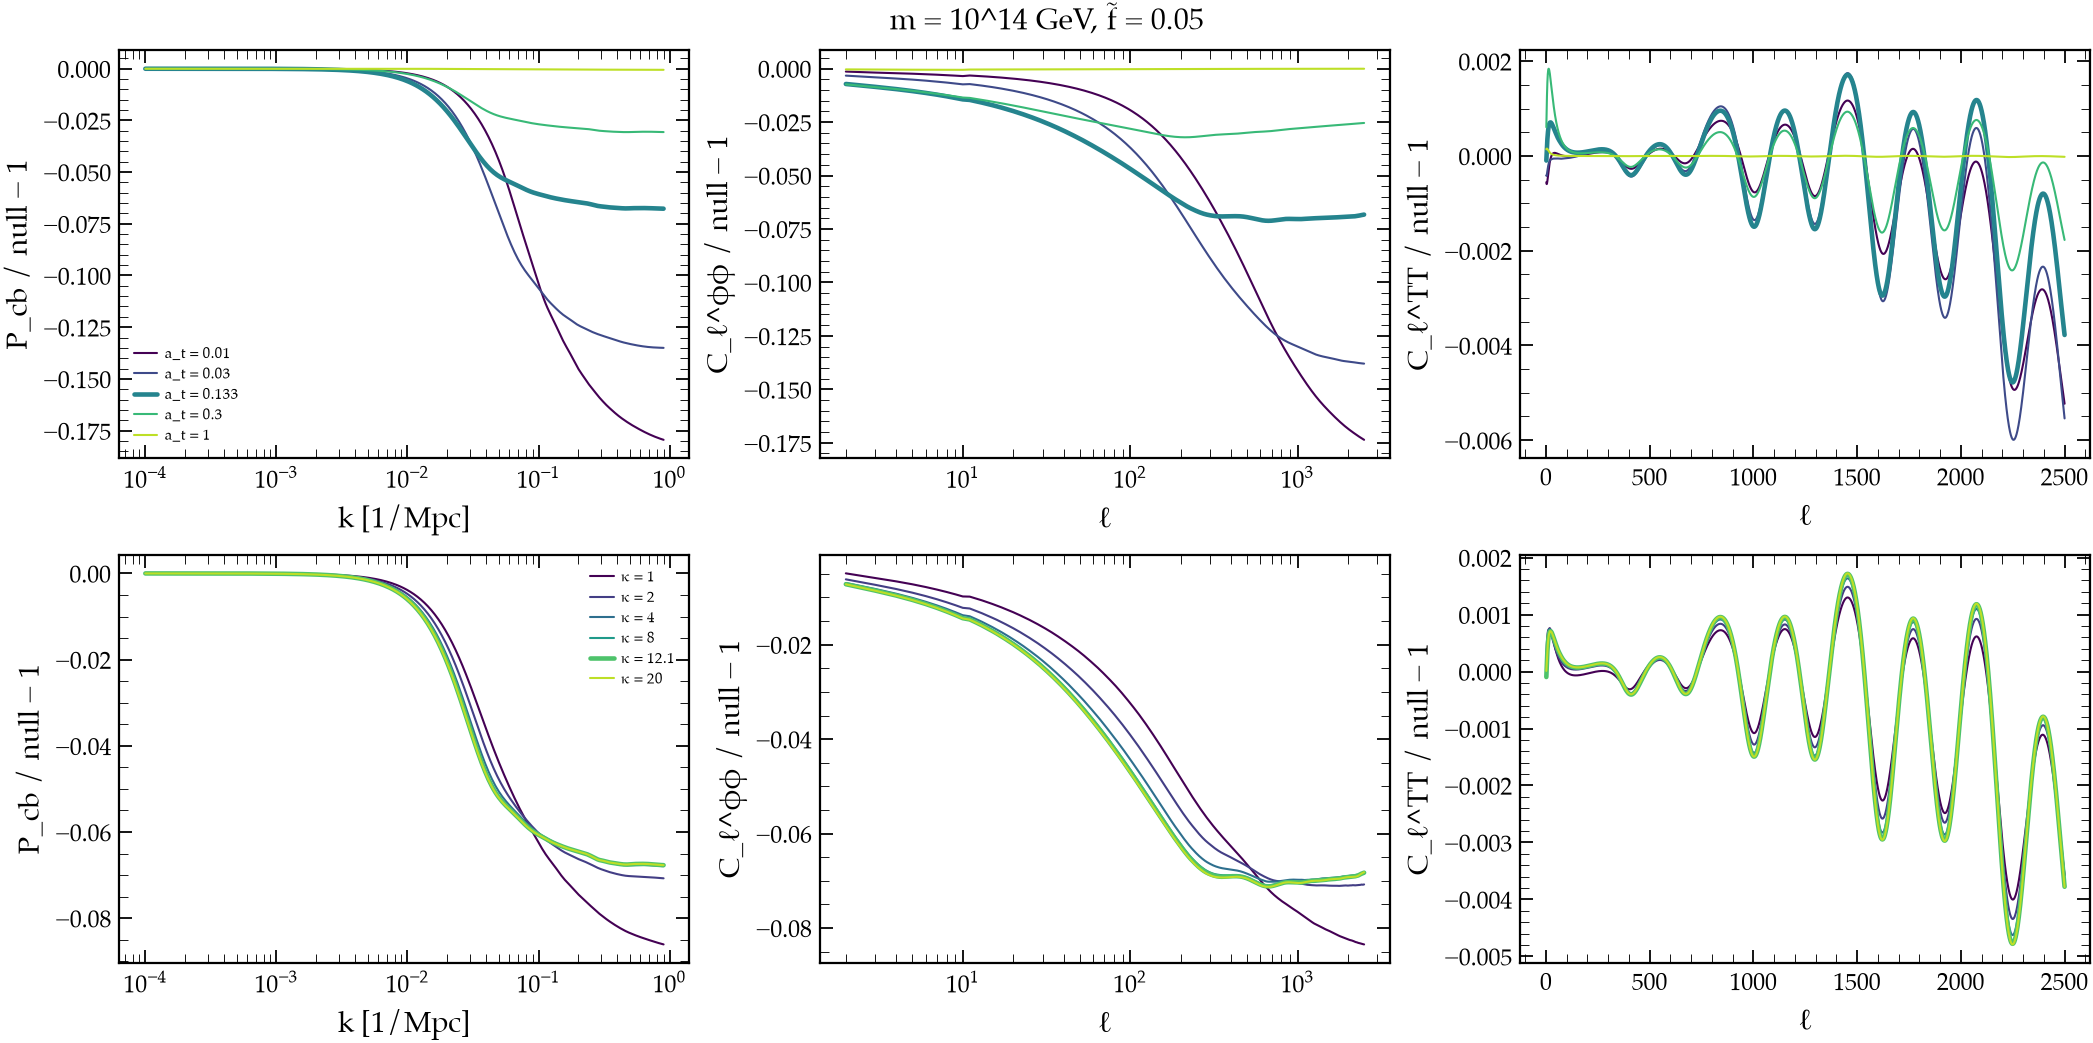

In [3]:
spec = dict(zip(SPEC_POINTS, runs([params(LM_SPEC, F_SPEC, *kt) for kt in SPEC_POINTS])))

fig, axes = plt.subplots(2, 3, figsize=(14, 7), constrained_layout=True)
for row, (name, pts) in zip(axes, SLICES):
    pts = [kt for kt in pts if kt[1] >= A_MIN]
    for c, kt in zip(plt.cm.viridis(np.linspace(0, 0.9, len(pts))), pts):
        r = spec[kt]
        lab = '{} = {:g}'.format(name, kt[1] if name == 'a_t' else kt[0])
        lw = 2.2 if kt == (KAPPA, A_T) else 1.0
        row[0].semilogx(KK, r['pk_cb']/null['pk_cb'] - 1, color=c, lw=lw, label=lab)
        row[1].semilogx(ELL, r['pp']/null['pp'] - 1, color=c, lw=lw)
        row[2].plot(ELL, r['tt']/null['tt'] - 1, color=c, lw=lw)
    row[0].set_xlabel('k [1/Mpc]')
    row[0].set_ylabel('P_cb / null − 1')
    row[1].set_ylabel('C_ℓ^φφ / null − 1')
    row[2].set_ylabel('C_ℓ^TT / null − 1')
    for ax in row[1:]:
        ax.set_xlabel('ℓ')
    row[0].legend(fontsize=7)
fig.suptitle('m = 10^{} GeV, f̃ = {:g}'.format(LM_SPEC, F_SPEC))
plt.show()

## 2. f̃₄ across the box

For each (m, κ, a_t), f̃ is moved until Δχ² against the null reaches 4: two starting values per mass, then
power-law steps in log Δχ²–log f̃ until a run lands within 5% of 4 with a run on the other side, and f̃₄
is interpolated between the bracketing pair. f̃₄ = ∞ means Δχ² stays below 4 up to f̃ = 0.999.

Physically f_acc < a_t^−κ, i.e. f̃ < 1/(1 + a_t^κ) (`f_tilde_max`; CLASS warns above it). This binds only for
slow or late transitions: f̃ < 0.5 at a_t = 1 for every κ. An f̃₄ above the bound counts as unconstrained (∞);
section 4 keeps the raw f̃₄.

In [4]:
hist, unfinished = search(POINTS, runs, null)
failed = [(pt, f) for pt, h in hist.items() for f, c in h.items() if not np.isfinite(c)]
print('{} runs; failed: {}; unfinished: {}'.format(sum(map(len, hist.values())), failed or 'none',
                                                   list(unfinished) or 'none'))
F4 = {pt: f4(h) for pt, h in hist.items()}                          # raw, for section 4
F4P = {pt: f if f < f_tilde_max(*pt[1:]) else np.inf for pt, f in F4.items()}
print('above the bound, now unconstrained:',
      [(pt, round(F4[pt], 3)) for pt in F4 if pt[2] >= A_MIN and np.isfinite(F4[pt]) and np.isinf(F4P[pt])])

935 runs; failed: none; unfinished: [(15, 20, 0.001)]
above the bound, now unconstrained: [((12, 20, 1.0), 0.624), ((14, 4, 1.0), 0.656), ((16, 1, 0.3), 0.781), ((16, 1, 1.0), 0.984)]


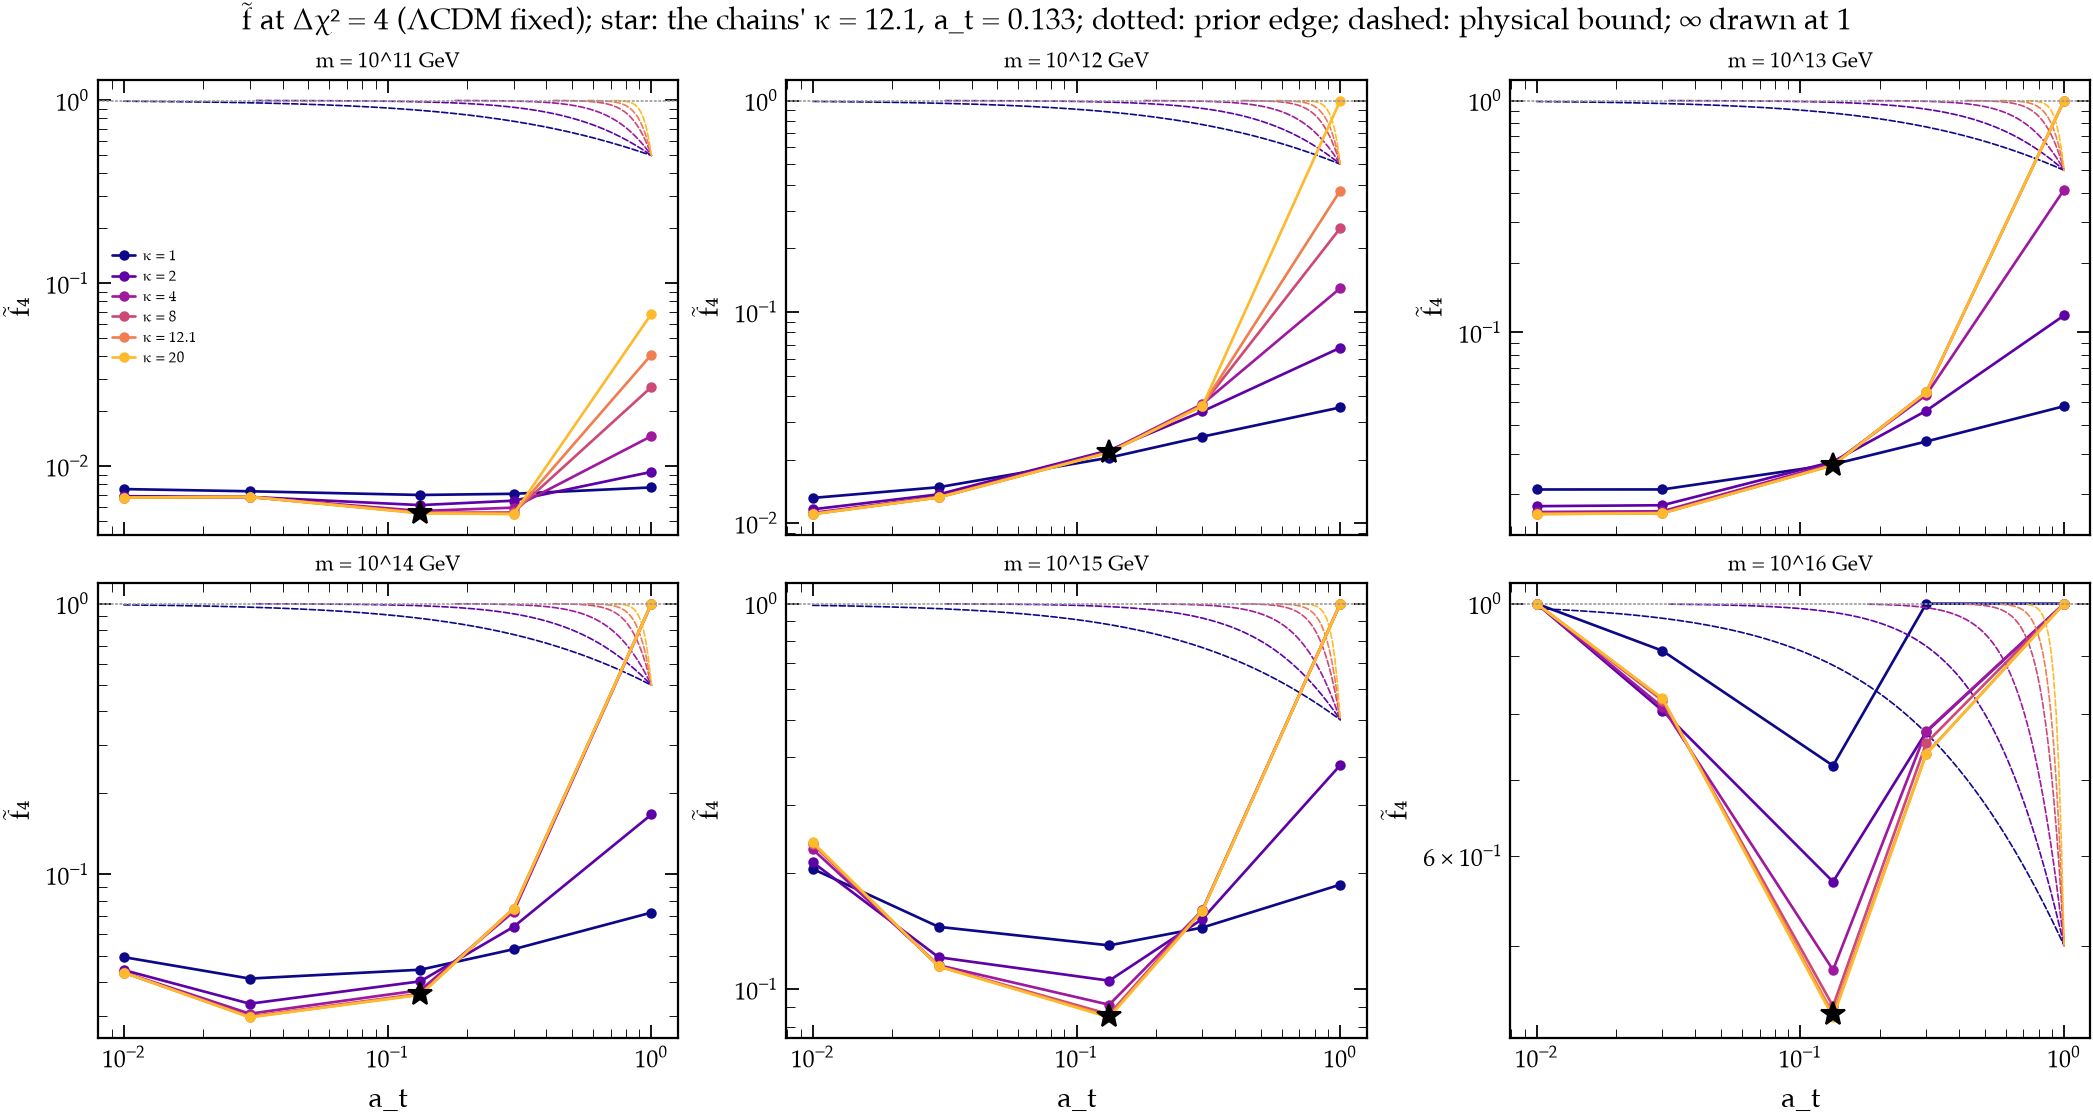

In [5]:
fig, axes = plt.subplots(2, 3, figsize=(14, 7.5), sharex=True, constrained_layout=True)
for ax, lm in zip(axes.flat, MASSES):
    for c, k in zip(plt.cm.plasma(np.linspace(0, 0.85, len(KAPPAS))), KAPPAS):
        ax.loglog(A_BOX, [min(F4P[lm, k, at], 1.0) for at in A_BOX], 'o-', color=c, ms=4, label='κ = {:g}'.format(k))
        a_fine = np.logspace(np.log10(A_MIN), 0, 200)
        bound = f_tilde_max(k, a_fine)
        ax.loglog(a_fine[bound < F_MAX], bound[bound < F_MAX], '--', color=c, lw=0.8)
    ax.plot(A_T, F4P[lm, KAPPA, A_T], '*', color='k', ms=12, zorder=5)
    ax.axhline(F_MAX, color='0.6', lw=0.8, ls=':')
    ax.set_title('m = 10^{} GeV'.format(lm), fontsize=10)
    ax.set_ylabel('f̃₄')
for ax in axes[-1]:
    ax.set_xlabel('a_t')
axes[0, 0].legend(fontsize=7)
fig.suptitle('f̃ at Δχ² = 4 (ΛCDM fixed); star: the chains\' κ = 12.1, a_t = 0.133; dotted: prior edge; dashed: physical bound; ∞ drawn at 1')
plt.show()

f̃₄ relative to the chains' choice over the box, for every κ and for κ ≥ 4.

In [6]:
def ratio(lm, k, at):
    return F4P[lm, k, at]/F4P[lm, KAPPA, A_T]


rows = []
for lm in MASSES:
    r_all = np.array([ratio(lm, k, at) for k in KAPPAS for at in A_BOX])
    r_steep = np.array([ratio(lm, k, at) for k in KAPPAS for at in A_BOX if k >= 4])
    rows.append({'log10 m': lm, 'f̃₄ (12.1, 0.133)': F4P[lm, KAPPA, A_T],
                 'min / chains': r_all.min(), 'max / chains': r_all.max(),
                 'min, κ ≥ 4': r_steep.min(), 'max, κ ≥ 4': r_steep.max(),
                 'κ 8–20, a_t 0.133': '{:.2f}–{:.2f}'.format(*sorted([ratio(lm, 8, A_T), ratio(lm, 20, A_T)]))})
show(pd.DataFrame(rows).set_index('log10 m'), {'f̃₄ (12.1, 0.133)': '{:.3g}'}, default='{:.2f}')

,"f̃₄ (12.1, 0.133)",min / chains,max / chains,"min, κ ≥ 4","max, κ ≥ 4","κ 8–20, a_t 0.133"
log10 m,,,,,,
11,0.00555,0.98,12.27,0.98,12.27,1.00–1.00
12,0.0216,0.51,inf,0.51,inf,1.00–1.00
13,0.0267,0.61,inf,0.61,inf,1.00–1.00
14,0.036,0.82,inf,0.82,inf,1.00–1.01
15,0.0851,0.99,inf,0.99,inf,0.99–1.01
16,0.435,0.99,inf,0.99,inf,0.99–1.02


## 3. Is the median birth enough?

f̃₄ relative to the chains' choice against z₅₀, coloured by κ. If the points of all κ fall on one curve, the
transition acts through when the daughters are born, and κ only matters through z₅₀. The right panel shows
which data carry Δχ² at the run closest to f̃₄.

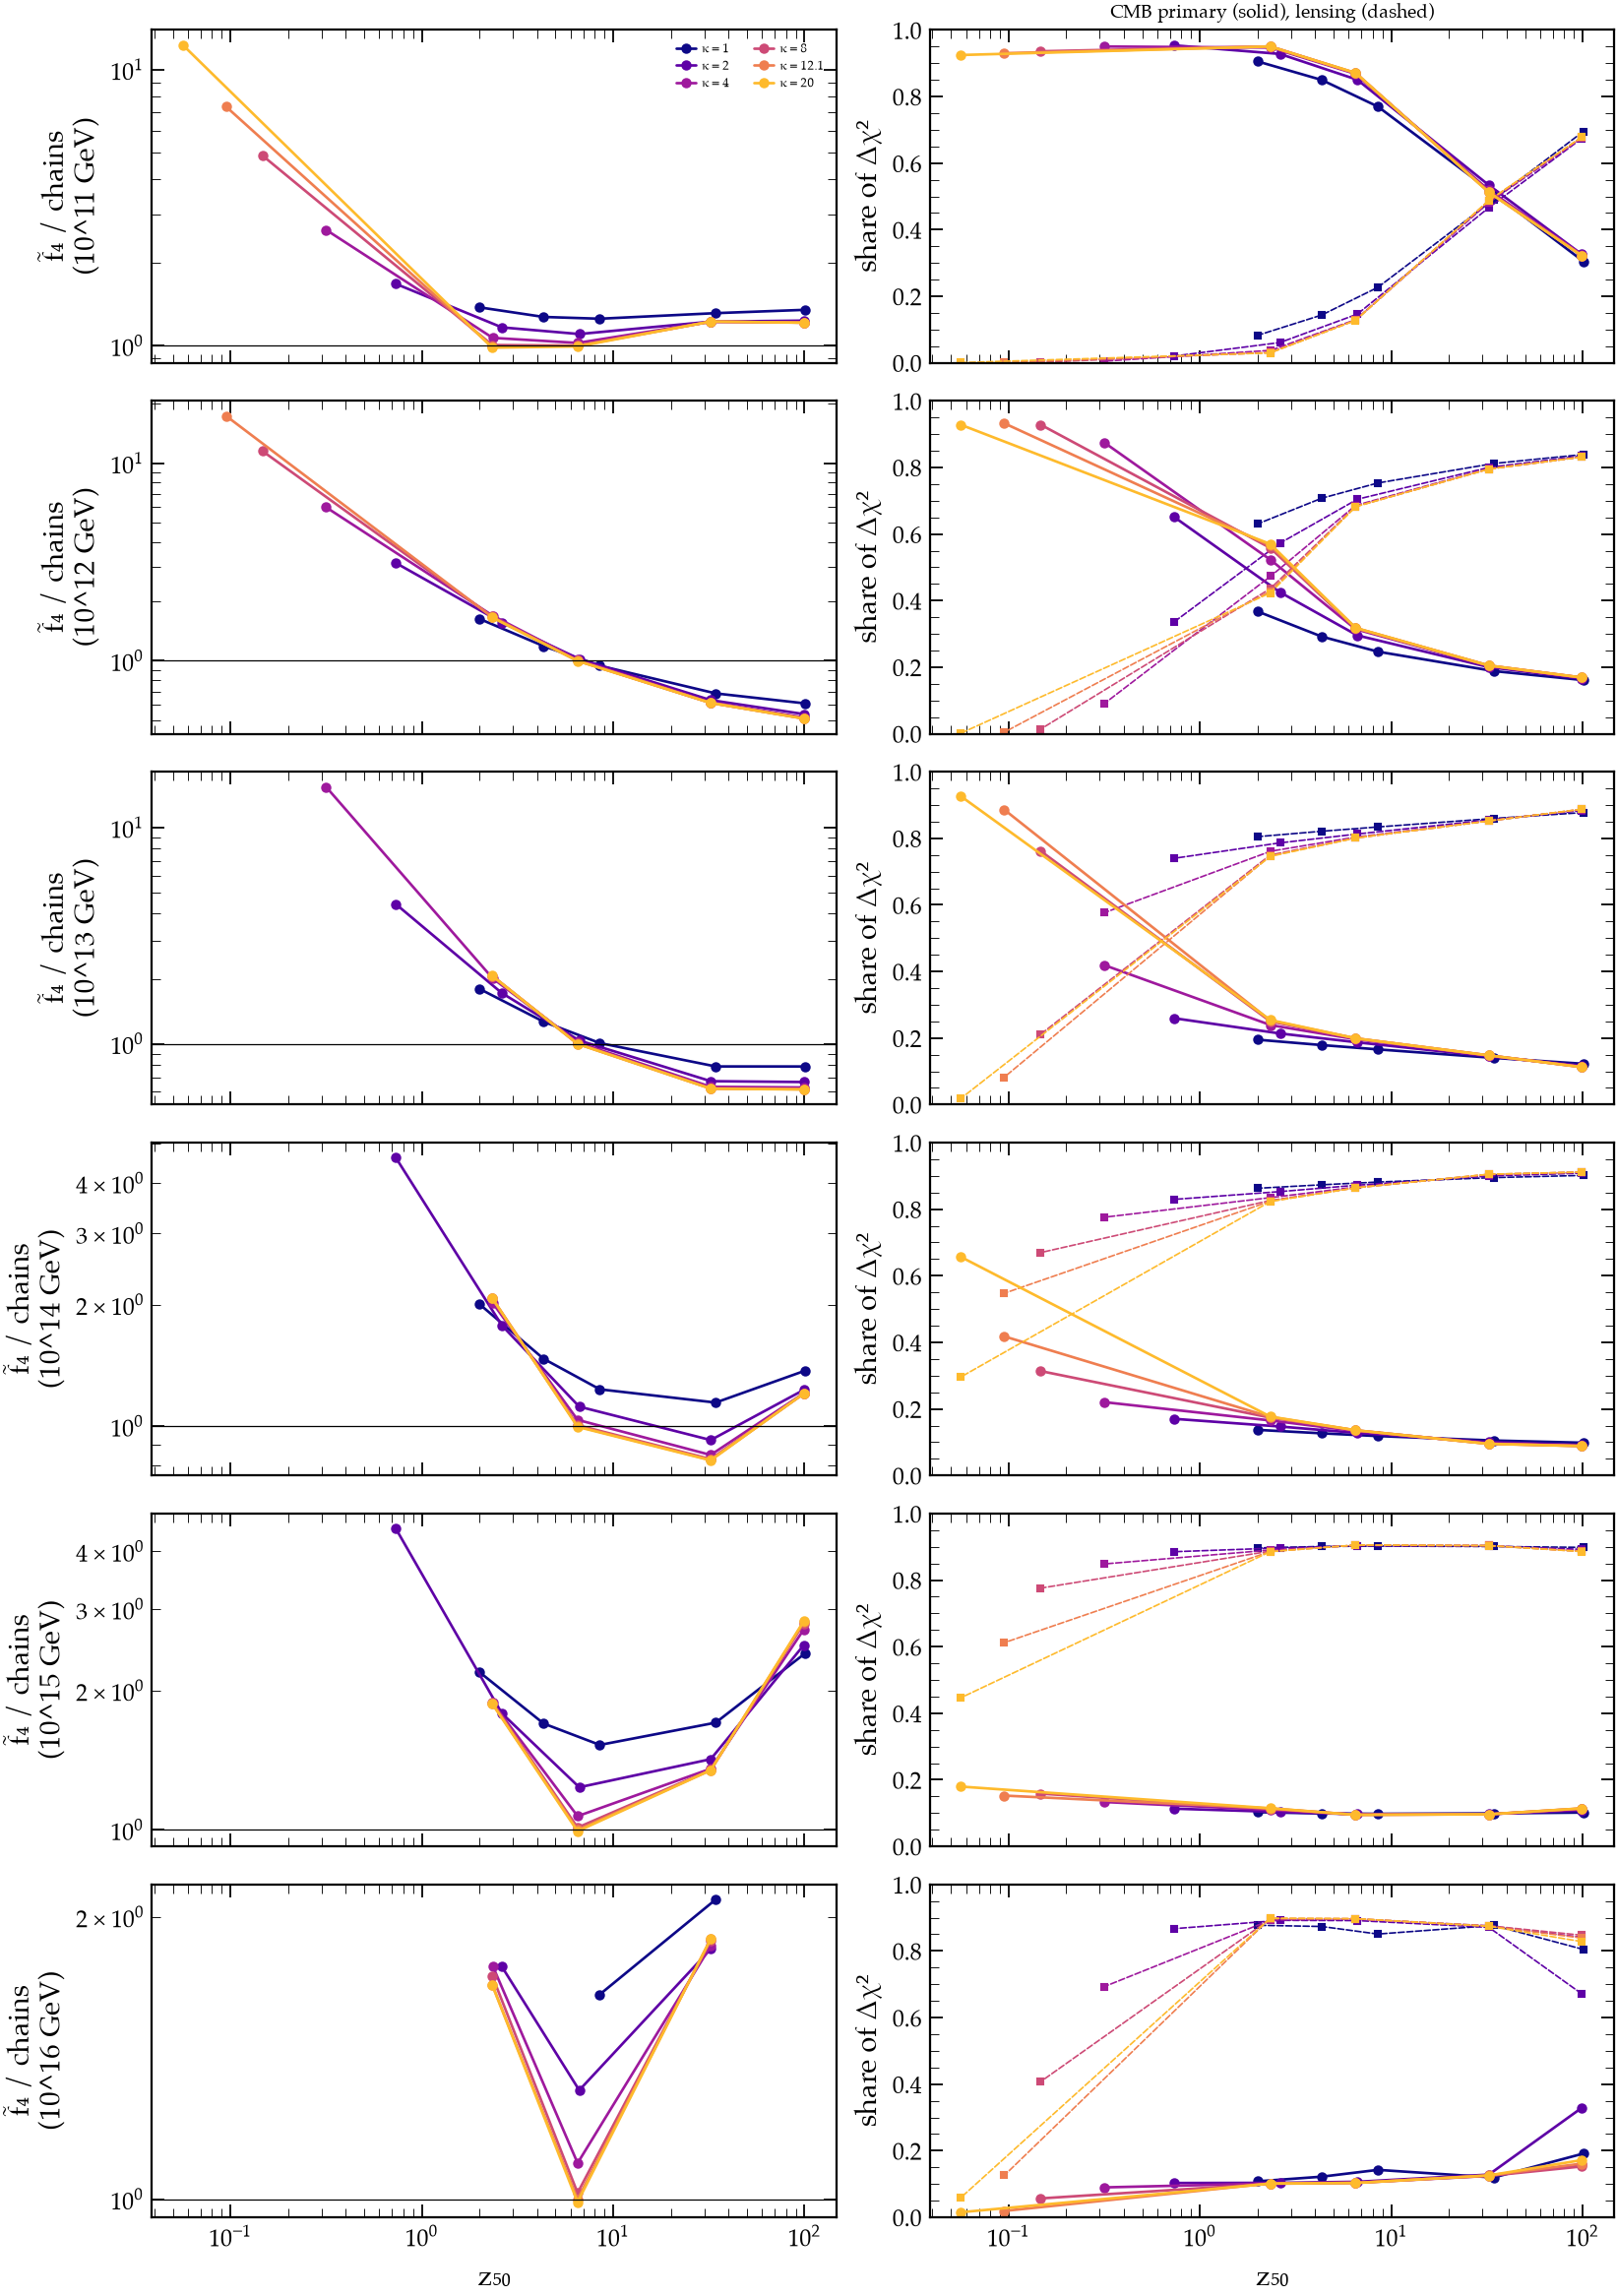

In [7]:
def parts_at_f4(pt):
    f = min(hist[pt], key=lambda f: abs(np.log(hist[pt][f]/CHI2_LIM)) if np.isfinite(hist[pt][f]) and hist[pt][f] > 0 else np.inf)
    return chi2_parts(runs([params(pt[0], f, *pt[1:])])[0], null)


fig, axes = plt.subplots(len(MASSES), 2, figsize=(11, 2.6*len(MASSES)), sharex=True, constrained_layout=True)
for (a1, a2), lm in zip(axes, MASSES):
    for c, k in zip(plt.cm.plasma(np.linspace(0, 0.85, len(KAPPAS))), KAPPAS):
        z = [B[k, at]['z50'] for at in A_BOX]
        a1.loglog(z, [ratio(lm, k, at) for at in A_BOX], 'o-', color=c, ms=4, label='κ = {:g}'.format(k))
        parts = [parts_at_f4((lm, k, at)) for at in A_BOX]
        a2.semilogx(z, [p['cmb']/p['total'] for p in parts], 'o-', color=c, ms=4)
        a2.semilogx(z, [p['lens']/p['total'] for p in parts], 's--', color=c, ms=3, lw=0.8)
    a1.axhline(1, color='k', lw=0.6)
    a1.set_ylabel('f̃₄ / chains\n(10^{} GeV)'.format(lm))
    a2.set_ylabel('share of Δχ²')
    a2.set_ylim(0, 1)
axes[0, 0].legend(fontsize=6, ncol=2)
axes[0, 1].set_title('CMB primary (solid), lensing (dashed)', fontsize=9)
for ax in axes[-1]:
    ax.set_xlabel('z₅₀')
plt.show()

## 4. Numerical check

At the corners of the grid as run (κ = 1, 20 × a_t = 10⁻³, 1) and the chains' choice, the run at f̃₄ (rounded)
is repeated with 401 daughter bins and `accdm_l_max` 35. The a_t = 10⁻³ corners lie below the box. *Δχ² grid* is
the high-resolution run against the production one; *signal shift* the relative change of Δχ² against the
null, which moves f̃₄ by about half as much, in the opposite direction.

In [8]:
pts = [(lm, k, at) for lm in MASSES for k, at in CORNERS if np.isfinite(F4[lm, k, at])]
pairs = [runs(list(checks(*pt, F4[pt]))) for pt in pts]
rows = [{'log10 m': lm, 'κ': k, 'a_t': at, 'f̃': F4[lm, k, at], 'Δχ² grid': chi2_parts(hi, lo)['total'],
         'signal shift': chi2_parts(hi, null)['total']/chi2_parts(lo, null)['total'] - 1}
        for (lm, k, at), (lo, hi) in zip(pts, pairs)]
show(pd.DataFrame(rows).set_index(['log10 m', 'κ', 'a_t']), {'signal shift': '{:+.2%}', 'f̃': '{:.3g}'}, default='{:.2e}')

f̃  Δχ² grid signal shift
log10 m κ    a_t                                  
11      1.0  0.001  0.00704  1.42e-05       -0.15%
        20.0 0.001  0.00416  1.36e-05       -0.05%
        1.0  1.000  0.00765  1.96e-05       -0.09%
        20.0 1.000   0.0681  1.29e-06       +0.01%
        12.1 0.133  0.00555  1.10e-05       -0.14%
12      1.0  0.001   0.0153  6.07e-05       -0.01%
        20.0 0.001   0.0126  1.13e-04       +0.15%
        1.0  1.000   0.0353  1.75e-04       -0.78%
        20.0 1.000    0.624  3.24e-05       +0.05%
        12.1 0.133   0.0216  1.34e-04       -1.03%
13      1.0  0.001   0.0354  2.76e-04       -0.01%
        20.0 0.001   0.0382  6.33e-04       +0.01%
        1.0  1.000    0.048  1.75e-04       -0.47%
        12.1 0.133   0.0267  3.45e-05       -0.54%
14      1.0  0.001    0.128  3.86e-03       -0.26%
        20.0 0.001    0.218  2.63e-02       -1.04%
        1.0  1.000   0.0723  3.39e-04       +0.08%
        12.1 0.133    0.036  2.68e-06       -0.02%
15      1.0  0.001    0.685  8.25e-02       -6.04%
        20.0 0.001    0.903  2.21e+00      -74.42%
        1.0  1.000    0.187  2.27e-03       +0.41%
        12.1 0.133   0.0851  3.37e-06       +0.07%
16      20.0 0.001    0.962  2.25e+00      -92.84%
        1.0  1.000    0.984  6.31e-02       +0.99%
        12.1 0.133    0.435  1.20e-05       -0.01%

## 5. Grid ladder in the failing corner

Where section 4 fails (heavy, early, f̃ → 1) and at neighbouring controls: Δχ² against the null (*signal*) for
daughter bins × `accdm_l_max`, and Δχ² of each grid against the finest, (801, 50). The scan runs (201, 17).

In [9]:
rows = []
for lm, k, at in LADDER_POINTS:
    for f in LADDER_F:
        res = {(b, L): runs([params(lm, f, k, at, **grid(b, L))])[0] for b in LADDER_BINS for L in LADDER_L}
        ref = res[LADDER_BINS[-1], LADDER_L[-1]]
        for b in LADDER_BINS:
            rows.append({'m, κ, a_t': '{:g}, {:g}, {:g}'.format(lm, k, at), 'f̃': f, 'bins': b,
                         **{'signal L{}'.format(L): chi2_parts(res[b, L], null)['total'] for L in LADDER_L},
                         **{'vs ref L{}'.format(L): chi2_parts(res[b, L], ref)['total'] for L in LADDER_L}})
show(pd.DataFrame(rows).set_index(['m, κ, a_t', 'f̃', 'bins']), default='{:.3g}')

signal L17 signal L35 signal L50 vs ref L17 vs ref L35  \
m, κ, a_t     f̃  bins                                                          
15, 1, 0.001  0.5 201        2.22       2.22       2.22       0.11       0.11   
                  401        2.07       2.07       2.07     0.0237     0.0237   
                  801        2.03       2.03       2.03   3.69e-12   2.53e-15   
              0.9 201        6.73       6.73       6.73      0.262      0.262   
                  401        6.22       6.22       6.22     0.0628     0.0628   
                  801        6.07       6.07       6.07   1.15e-12   1.73e-16   
15, 20, 0.001 0.5 201       0.547      0.547      0.547      0.226      0.226   
                  401       0.339      0.339      0.339     0.0117     0.0117   
                  801       0.343      0.343      0.343   4.63e-25          0   
              0.9 201        4.38       4.38       4.38       3.28       3.28   
                  401        1.11       1.11       1.11      0.114      0.114   
                  801        1.02       1.02       1.02   3.78e-26          0   
16, 20, 0.001 0.5 201       0.208      0.208      0.208      0.218      0.218   
                  401      0.0117     0.0117     0.0117     0.0106     0.0106   
                  801     0.00695    0.00695    0.00695          0          0   
              0.9 201        3.52       3.52       3.52       3.35       3.35   
                  401        0.17       0.17       0.17      0.129      0.129   
                  801      0.0176     0.0176     0.0176          0          0   
15, 20, 0.01  0.5 201        15.2       15.2       15.2    0.00367    0.00367   
                  401        15.3       15.3       15.3   5.02e-05   5.02e-05   
                  801        15.3       15.3       15.3   1.72e-13   3.38e-18   
              0.9 201        41.3       41.3       41.3      0.015      0.015   
                  401        41.5       41.5       41.5   0.000139   0.000139   
                  801        41.5       41.5       41.5   2.88e-15    1.5e-19   
16, 20, 0.01  0.5 201       0.284      0.284      0.284    0.00374    0.00374   
                  401       0.288      0.288      0.288   5.71e-05   5.71e-05   
                  801       0.288      0.288      0.288   1.46e-24          0   
              0.9 201       0.868      0.868      0.868     0.0151     0.0151   
                  401       0.877      0.877      0.877   0.000121   0.000121   
                  801       0.878      0.878      0.878   3.23e-25          0   
14, 20, 0.001 0.5 201        18.1       18.1       18.1       0.24       0.24   
                  401        17.9       17.9       17.9    0.00727    0.00727   
                  801        17.9       17.9       17.9   5.02e-15   5.52e-20   
              0.9 201        48.8       48.8       48.8       0.87       0.87   
                  401        47.9       47.9       47.9     0.0508     0.0508   
                  801        48.2       48.2       48.2   3.18e-19   2.82e-22   

                       vs ref L50  
m, κ, a_t     f̃  bins             
15, 1, 0.001  0.5 201        0.11  
                  401      0.0237  
                  801           0  
              0.9 201       0.262  
                  401      0.0628  
                  801           0  
15, 20, 0.001 0.5 201       0.226  
                  401      0.0117  
                  801           0  
              0.9 201        3.28  
                  401       0.114  
                  801           0  
16, 20, 0.001 0.5 201       0.218  
                  401      0.0106  
                  801           0  
              0.9 201        3.35  
                  401       0.129  
                  801           0  
15, 20, 0.01  0.5 201     0.00367  
                  401    5.02e-05  
                  801           0  
              0.9 201       0.015  
                  401    0.000139  
                  801           0  
16, 20, 